# Week 2 - Exploratory Data Analysis: NextGenLearners Applicant Insights

## Setup
Dataset loaded successfully. Application Date parsed as datetime. No major missing values in key columns.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("applicants_cleaned.csv", parse_dates=["Application Date"])

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    73 non-null     object        
 1   Email             73 non-null     object        
 2   Phone             73 non-null     int64         
 3   Domain Applied    60 non-null     object        
 4   University        73 non-null     object        
 5   Application Date  21 non-null     datetime64[ns]
 6   Status            73 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.1+ KB


In [6]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ali Farooq,ali.farooq1@example.com,364944897,App Development,Government College University Faisalabad,2026-08-08,Selected
1,Saad Farooq,saad.farooq2@example.com,378075619,NaN,COMSATS University,NaT,Under Review
2,Noor Ali,noor.ali3@example.com,348405908,Graphic Design,The University of Faisalabad,NaT,Under Review
3,LAIBA SIDDIQUI,laiba.siddiqui4@example.com,326682487,Digital Marketing,The University of Faisalabad,2026-10-12,Under Review
4,Iqra Farooq,iqra.farooq5@example.com,372754275,Graphic Design,COMSATS University,NaT,Under Review


##1. Which Domain Received the Most Applications?


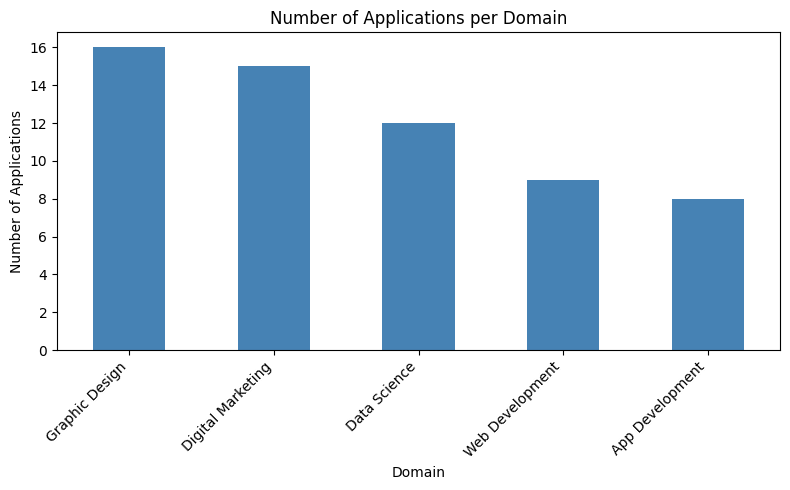

In [7]:
domain_counts = df['Domain Applied'].value_counts()

plt.figure(figsize=(8,5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Markdown : Graphic Design received the highest number of applications, followed by Digital Marketting, Data Science and Web Development. App Development had fewer applicants comparatively.


## 2. How Did Applications Trend Over Time?


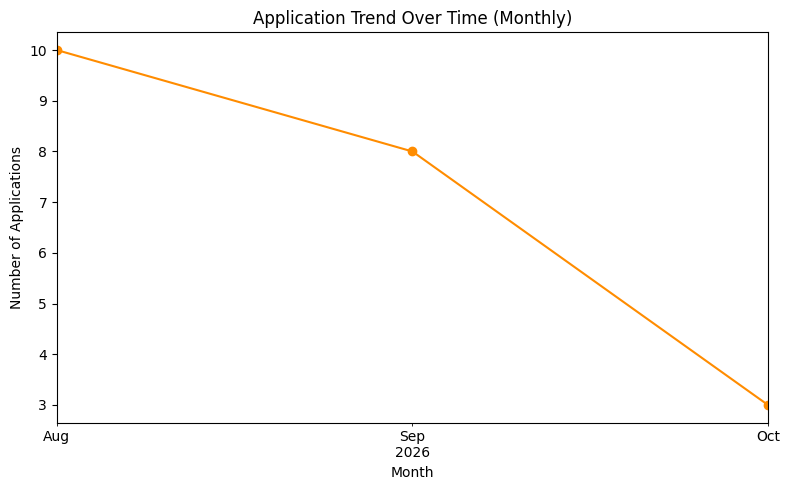

In [8]:
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()

plt.figure(figsize=(8,5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

## Markdown : Applications peaked in August 2026 and showed another rise in September, then declined toward October.


## 3. What is the Overall Application Status and Per Domain?


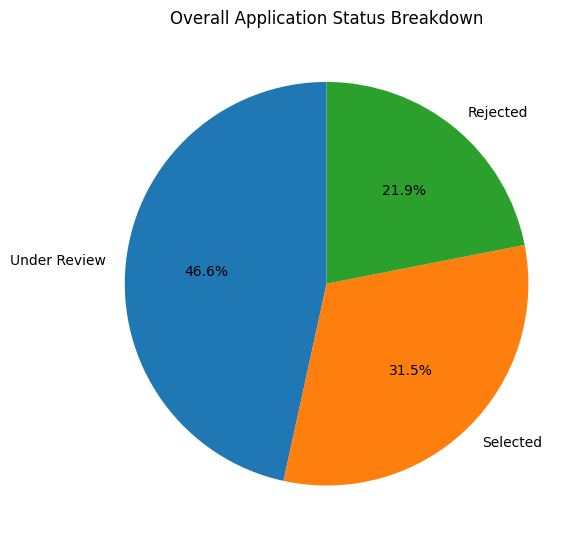

In [10]:
status_counts = df['Status'].value_counts()

plt.figure(figsize=(6,6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('')
plt.tight_layout()
plt.show()

status_by_domain = pd.pivot_table(df,index='Domain Applied',columns='Status',values='Applicant Name',aggfunc='count',fill_value=0)

## Markdown : Overall, most applications are under review.Then the selected applications has a large portion.

## 4. What is the Overall Application Acceptance Rate and Per Domain?

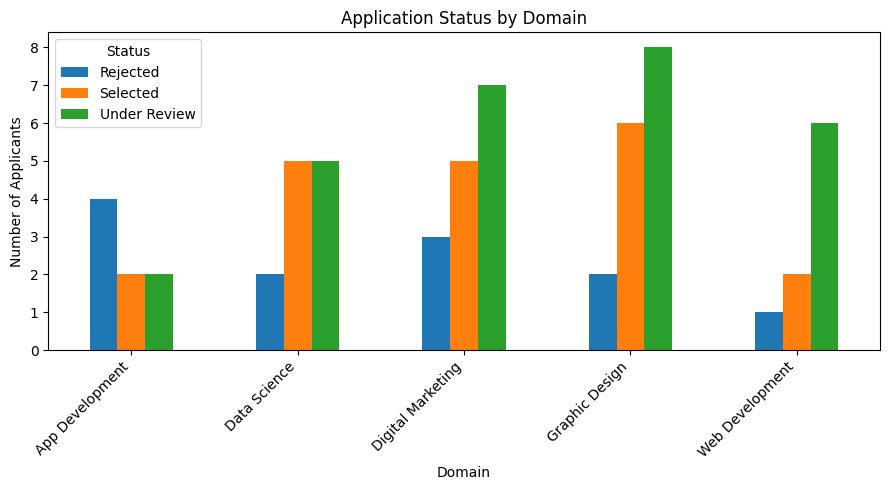

In [11]:
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100

status_by_domain.plot(kind='bar', figsize=(9,5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

## Markdown : Graphic Design has the highest Acceptance Rate compared to Data Science and Digital Marketting.On the Other Hand, App and Web development has the lowest Acceptance Rate.

## 5 . Which Universities Sent the Most Applicants?


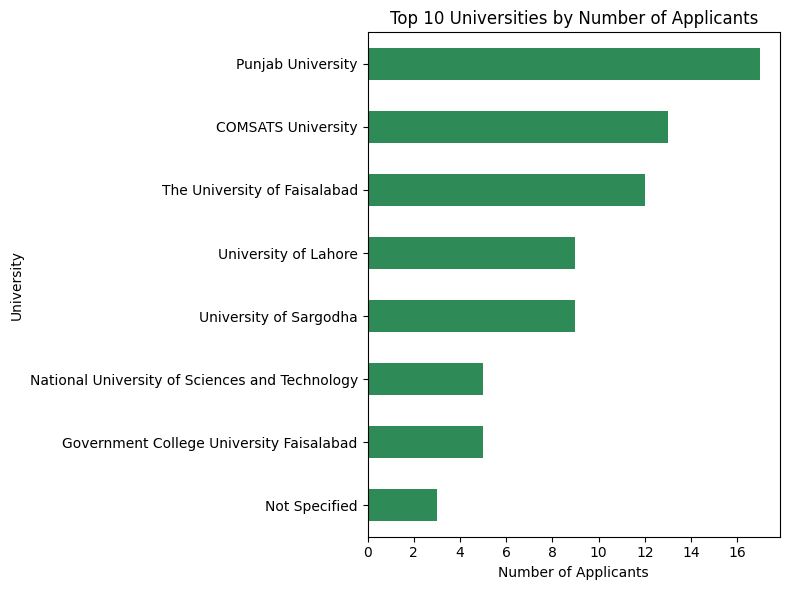

In [12]:
top_universities = df['University'].value_counts().head(10)

plt.figure(figsize=(8,6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

## Markdown : Punjab University contributed the highest number of applicants, followed by The University of Faisalabad and COMSATS University.


## 6. Bonus Chart: Applications by Day of Week


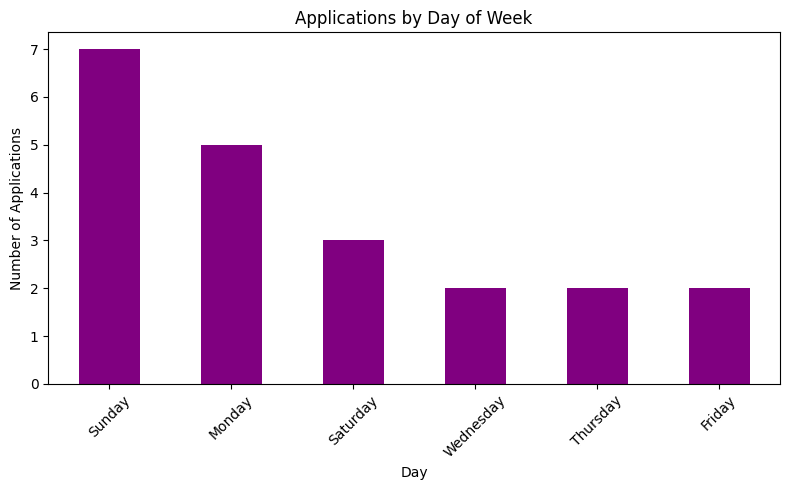

In [13]:
df['DayOfWeek'] = df['Application Date'].dt.day_name()
day_counts = df['DayOfWeek'].value_counts()

plt.figure(figsize=(8,5))
day_counts.plot(kind='bar', color='purple')
plt.title('Applications by Day of Week')
plt.xlabel('Day')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Markdown : Most applications were submitted on weekends, with Sunday showing the highest activity.


## Key Insights
-  Graphic Design is the most popular domain, followed by Digital Marketting.
- Applications peaked in August 2026 and showed another rise in September.
- Acceptance rates vary: smaller domains sometimes show higher success percentages.
- Punjab University, The University of Faisalabad, and COMSATS University dominate applicant sources.
- Most applications are submitted on weekends, especially Sundays.
